# Laporan Akhir Analisis Performa Pemrosesan Gambar

Pada tahap akhir ini saya menjalankan ulang sequential, thread 2/4, dan process 2/4 dengan tujuh pengulangan per-kondisi. Ada dua workload dan lima konfigurasi, sehingga totalnya 70 pengukuran. Saya menambah pengulangan untuk melihat konsistensi hasil yang sebelumnya hanya diukur tiga kali.

Dataset, transformasi, jumlah gambar, chunk size, urutan yang diputar, dan monitoring process tree tetap sama dengan notebook 03. Saya tidak menggabungkan hasil lama ke rata-rata baru. Seluruh angka analisis dan laporan akhir berasal dari rangkaian notebook ini.

Saya menggunakan rata-rata, median, SD, CV, rentang waktu, dan konfigurasi tercepat tiap putaran untuk membaca hasil. Statistik tersebut bersifat deskriptif; saya belum menganggapnya sebagai uji signifikansi atau bukti bahwa satu konfigurasi selalu tercepat pada semua komputer.

## 1. Memastikan environment dan dataset

Saya menggunakan Python dari `.venv` project dan 10.000 gambar dari batch pertama CIFAR-10. Input gambar tetap RGB 32 × 32; transformasi resize memakai ukuran kerja 64 × 64 seperti tahap sebelumnya.

Cell ini memeriksa environment serta parameter. Data dibaca ulang di proses benchmark sebelum timer dimulai.

In [1]:
from pathlib import Path
import sys
import subprocess
import json
import inspect
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image as NotebookImage

PROJECT = Path.cwd().resolve()
PYTHON = PROJECT / ".venv" / "Scripts" / "python.exe"
assert Path(sys.prefix).resolve() == (PROJECT / ".venv").resolve(), "Pilih kernel .venv project."
sys.path.insert(0, str(PROJECT / "src"))
from dataset import load_batch
from image_processing import TRANSFORM_CONFIG
from parallel_processing import process_chunk, run_method
from resource_monitor import ResourceMonitor
images, labels = load_batch()
assert images.shape == (10000, 32, 32, 3)
print("Python:", sys.executable)
print("Input:", images.shape, images.dtype)
print("Transformasi:", TRANSFORM_CONFIG)

Python: C:\Lucky\Binus University\S9\Operating System\Operating-System-Assignment\.venv\Scripts\python.exe
Input: (10000, 32, 32, 3) uint8
Transformasi: {'resize': [64, 64], 'resampling': 'BILINEAR', 'light': ['resize', 'grayscale'], 'heavy': ['resize', 'rotate', 'gaussian_blur', 'sharpen', 'color', 'find_edges'], 'rotation_degrees': 15, 'rotation_expand': False, 'blur_radius': 2, 'color_factor': 1.2}


## 2. Perbedaan thread dan process

Thread pengolah bekerja di satu proses dan dapat membaca array input yang sama. Worker process mempunyai interpreter serta ruang alamat sendiri. Pada implementasi ini, chunk array dikirim ke worker melalui serialization/IPC, lalu byte hasil dikirim kembali ke parent.

Process menghindari satu GIL bersama antar-worker, tetapi tetap memiliki biaya startup dan komunikasi. Library native pada threading juga dapat melepas GIL, sehingga saya tidak menganggap multiprocessing otomatis paling cepat.

Saya menggunakan `ProcessPoolExecutor` dengan start method `spawn`. Worker berupa fungsi pada file `.py` yang bisa di-import, dan entry point memakai `if __name__ == '__main__'`. Notebook memanggil file tersebut melalui Python project, sehingga worker Windows dapat menjalankan entry point dengan aman tanpa mengulang seluruh notebook.

Satu task berisi 100 gambar; paling banyak `2 × worker` task belum dikonsumsi. Tidak ada shared-memory dataset. Output diambil sesuai urutan task untuk menjaga urutan hash sama dengan sequential.

In [2]:
print(inspect.getsource(process_chunk))
print(inspect.getsource(run_method))

def process_chunk(images: np.ndarray, workload: str) -> list[bytes]:
    # Pada process input merupakan salinan chunk; pada thread berupa view shared.
    images.flags.writeable = False
    return [process_image(pixels, workload).tobytes() for pixels in images]

def run_method(images, workload, method, workers, chunk_size=100):
    if method not in ("sequential", "threading", "multiprocessing"):
        raise ValueError("Metode tidak dikenal")
    if (method == "sequential" and workers != 1) or (method != "sequential" and workers not in (2, 4)):
        raise ValueError("Sequential: 1 worker; pool: 2/4 worker")
    if len(images) < 1 or chunk_size < 1:
        raise ValueError("Input dan chunk harus positif")
    gc.collect()
    images.flags.writeable = False
    parent = psutil.Process()
    monitor = ResourceMonitor(interval=0.05)
    digest = hashlib.sha256()
    processed = 0
    monitor.start()
    cpu_before = parent.cpu_times()
    start = perf_counter()
    monitor.origin = st

## 3. Pengukuran CPU dan RAM yang mencakup worker

Jika hanya parent yang dicatat, RAM dan CPU worker multiprocessing tidak terlihat. Karena itu, pada tahap ini saya memakai monitor **process tree** untuk seluruh metode: parent benchmark beserta descendant processes yang masih hidup. Monitor memakai satu thread sampling tambahan pada semua konfigurasi; thread ini hanya mencatat resource.

RAM adalah maksimum **jumlah RSS pada snapshot yang sama**, bukan jumlah maksimum tiap proses yang terjadi pada waktu berbeda. Snapshot diambil sekitar setiap 50 ms, ditambah sebelum shutdown pool dan di akhir. Halaman memori shared mungkin dihitung lebih dari sekali; puncak singkat juga bisa terlewat. Angka ini bukan ukuran memori unik/PSS.

CPU parent dihitung dari perubahan CPU time selama timer. CPU child memakai nilai kumulatif terakhir yang sempat diamati, termasuk startup worker. CPU teardown setelah snapshot terakhir mungkin tidak tercatat, jadi kolom CPU tree diberi nama *sampled* dan dibaca sebagai estimasi. Skala 100% setara satu logical CPU, bukan seluruh komputer.

Karena metode monitoring diperbarui, saya tidak mencampurkan angka CPU/RAM notebook 01/02 ke tabel akhir ini.

In [3]:
print(inspect.getsource(ResourceMonitor))

class ResourceMonitor:
    def __init__(self, interval=0.05):
        self.parent = psutil.Process()
        self.interval = interval
        self.stop_event = Event()
        self.lock = Lock()
        self.samples = []
        self.child_cpu = {}
        self.origin = perf_counter()
        self.thread = Thread(target=self._poll, name="resource-sampler", daemon=True)

    def sample(self):
        # Lock mencegah snapshot manual dan snapshot monitor bertabrakan.
        with self.lock:
            parent_rss = self.parent.memory_info().rss / 1024**2
            tree_rss = parent_rss
            child_count = 0
            for child in self.parent.children(recursive=True):
                try:
                    key = (child.pid, child.create_time())
                    times = child.cpu_times()
                    self.child_cpu[key] = max(self.child_cpu.get(key, 0), times.user + times.system)
                    tree_rss += child.memory_info().rss / 1024**2
                    chil

## 4. Rancangan eksperimen

| Pengaturan | Nilai |
|---|---|
| Metode | Sequential; thread 2/4; process 2/4 |
| Workload | LIGHT dan HEAVY dengan parameter tetap |
| Input | 10.000 gambar, batch pertama yang sama |
| Pengulangan | 7 per-kondisi; total 70 pengukuran |
| Warm-up | 50 gambar pada parent, sebelum timer |
| Pool | Baru pada setiap run; worker process belum di-warm-up |
| Pengukuran | Proses benchmark baru pada setiap run |
| Urutan | 10 kondisi diputar 3 posisi tiap pengulangan |

LIGHT memakai resize lalu grayscale. HEAVY memakai resize, rotate, blur, sharpen, color adjustment, dan edge detection.

Timer mencakup pekerjaan pengolahan, konversi byte, hash, monitoring, pembuatan/penutupan pool, serta IPC pada process. Startup interpreter benchmark, load dataset, warm-up parent, CSV, dan grafik berada di luar timer. Dengan demikian, saya mengukur skenario pool baru untuk satu pekerjaan, bukan pool yang digunakan berkali-kali.

In [4]:
NUMBER_OF_IMAGES = 10000
REPETITIONS = 7
WARMUP_IMAGES = 50
completed = subprocess.run(
    [str(PYTHON), str(PROJECT / "main.py"), "--experiment", "comparison",
     "--images", str(NUMBER_OF_IMAGES), "--repetitions", str(REPETITIONS),
     "--warmup", str(WARMUP_IMAGES)],
    cwd=PROJECT, capture_output=True, text=True, check=True,
)
print(completed.stdout)
if completed.stderr:
    print(completed.stderr)
result_line = next(line for line in completed.stdout.splitlines() if line.startswith("RESULT_DIR="))
RESULT_DIR = Path(result_line.removeprefix("RESULT_DIR="))
status = json.loads((RESULT_DIR / "status.json").read_text(encoding="utf-8"))
assert status["complete"] and status["measured_runs"] == 10 * REPETITIONS
environment = json.loads((RESULT_DIR / "environment.json").read_text(encoding="utf-8"))
display(pd.DataFrame({"Informasi": ["Waktu", "OS", "Python", "CPU", "Logical CPU", "RAM terpasang (GiB)"],
                      "Nilai": [environment["timestamp"], environment["os"], environment["python"],
                                environment["cpu"], environment["logical_cpus"], round(environment["total_ram_gib"], 2)]}))

Run 1/7: LIGHT sequential 1
  0.588 s | 17007.2 gambar/s | RSS tree 66.5 MiB
Run 1/7: LIGHT threading 2
  0.934 s | 10701.1 gambar/s | RSS tree 68.3 MiB
Run 1/7: LIGHT threading 4
  0.925 s | 10809.5 gambar/s | RSS tree 70.5 MiB
Run 1/7: LIGHT multiprocessing 2
  0.726 s | 13773.9 gambar/s | RSS tree 145.7 MiB
Run 1/7: LIGHT multiprocessing 4
  0.687 s | 14564.5 gambar/s | RSS tree 221.2 MiB
Run 1/7: HEAVY sequential 1
  4.626 s | 2161.7 gambar/s | RSS tree 66.8 MiB
Run 1/7: HEAVY threading 2
  3.415 s | 2928.0 gambar/s | RSS tree 69.4 MiB
Run 1/7: HEAVY threading 4
  3.244 s | 3083.1 gambar/s | RSS tree 72.5 MiB
Run 1/7: HEAVY multiprocessing 2
  2.642 s | 3785.2 gambar/s | RSS tree 145.7 MiB
Run 1/7: HEAVY multiprocessing 4
  1.913 s | 5228.4 gambar/s | RSS tree 226.4 MiB
Run 2/7: LIGHT multiprocessing 2
  0.724 s | 13812.0 gambar/s | RSS tree 145.6 MiB
Run 2/7: LIGHT multiprocessing 4
  0.680 s | 14708.0 gambar/s | RSS tree 222.5 MiB
Run 2/7: HEAVY sequential 1
  4.756 s | 2102.7 ga

,Informasi,Nilai
0,Waktu,2026-10-05T13:58:45.282190+07:00
1,OS,Windows-10-10.0.26200-SP0
2,Python,3.11.9
3,CPU,Intel(R) Core(TM) Ultra 9 185H
4,Logical CPU,22
5,RAM terpasang (GiB),31.43


## 5. Memeriksa hasil setiap run

Sebelum membandingkan performa, saya memeriksa jumlah pengukuran, jumlah gambar, rumus throughput, dan kesamaan hash output. SHA-256 harus sama antar-metode dan antar-run untuk workload yang sama.

Seluruh run tetap ditampilkan. Jika ada run lambat, saya tidak membuangnya hanya agar rata-rata lebih bagus. Validasi hash tidak menilai kualitas visual, tetapi membantu memastikan pekerjaan yang dibandingkan menghasilkan byte output yang sama.

In [5]:
raw = pd.read_csv(RESULT_DIR / "raw_results.csv")
groups = raw.groupby(["workload", "method", "workers"])
assert len(raw) == 10 * REPETITIONS and len(groups) == 10
assert groups.size().eq(REPETITIONS).all()
assert (raw.images == NUMBER_OF_IMAGES).all()
assert raw.groupby("workload").output_sha256.nunique().eq(1).all()
assert (raw.time_s > 0).all()
assert np.allclose(raw.throughput_images_s * raw.time_s, NUMBER_OF_IMAGES)
assert (raw.rss_tree_peak_sampled_mib >= raw.rss_tree_before_mib).all()
assert (raw.rss_tree_peak_sampled_mib >= raw.rss_parent_peak_sampled_mib).all()
process_rows = raw[raw.method == "multiprocessing"]
assert (process_rows.child_processes_max_sampled >= process_rows.workers).all()
assert (process_rows.child_cpu_seconds_sampled > 0).all()
display(raw[["run", "workload", "method", "workers", "time_s", "throughput_images_s",
             "cpu_tree_sampled_percent", "rss_tree_peak_sampled_mib"]].round(3))
print("Validasi seluruh run, worker yang terpantau, jumlah input, throughput, RSS, dan hash: lolos.")

,run,workload,method,workers,time_s,throughput_images_s,cpu_tree_sampled_percent,rss_tree_peak_sampled_mib
0,1,light,sequential,1,0.588,17007.158,98.323,66.527
1,1,light,threading,2,0.934,10701.143,123.732,68.320
2,1,light,threading,4,0.925,10809.490,145.253,70.516
3,1,light,multiprocessing,2,0.726,13773.858,187.238,145.699
4,1,light,multiprocessing,4,0.687,14564.457,332.252,221.250
...,...,...,...,...,...,...,...,...
65,7,light,multiprocessing,2,0.753,13288.191,197.247,146.266
66,7,light,multiprocessing,4,0.672,14889.560,337.342,222.469
67,7,heavy,sequential,1,4.750,2105.481,96.721,66.676
68,7,heavy,threading,2,3.314,3017.349,159.825,69.461


Validasi seluruh run, worker yang terpantau, jumlah input, throughput, RSS, dan hash: lolos.


## 6. Perbandingan waktu, throughput, dan speedup

Saya memakai rata-rata waktu sequential dari rangkaian ini sebagai pembilang speedup untuk workload yang sama. Speedup di atas 1 berarti lebih cepat; di bawah 1 berarti lebih lambat. Efficiency adalah `speedup / worker × 100%`, bukan pemakaian CPU.

Rata-rata throughput dihitung dari throughput setiap run. Error bar waktu menunjukkan sample SD, bukan confidence interval atau bukti signifikansi statistik.

,workload,method,workers,runs,mean_time_s,std_time_s,mean_throughput_images_s,speedup,efficiency_percent,time_cv_percent
0,heavy,sequential,1,7,4.672,0.106,2141.471,1.000,100.000,2.264
1,heavy,threading,2,7,3.357,0.065,2979.734,1.392,69.580,1.929
2,heavy,threading,4,7,3.275,0.126,3057.231,1.427,35.663,3.860
3,heavy,multiprocessing,2,7,2.639,0.033,3790.117,1.770,88.520,1.238
4,heavy,multiprocessing,4,7,1.954,0.052,5121.123,2.391,59.776,2.668
5,light,sequential,1,7,0.585,0.021,17101.828,1.000,100.000,3.519
6,light,threading,2,7,0.947,0.078,10613.895,0.618,30.893,8.244
7,light,threading,4,7,0.938,0.043,10680.205,0.624,15.602,4.600
8,light,multiprocessing,2,7,0.737,0.022,13580.509,0.794,39.716,3.042
9,light,multiprocessing,4,7,0.682,0.005,14668.439,0.859,21.465,0.765


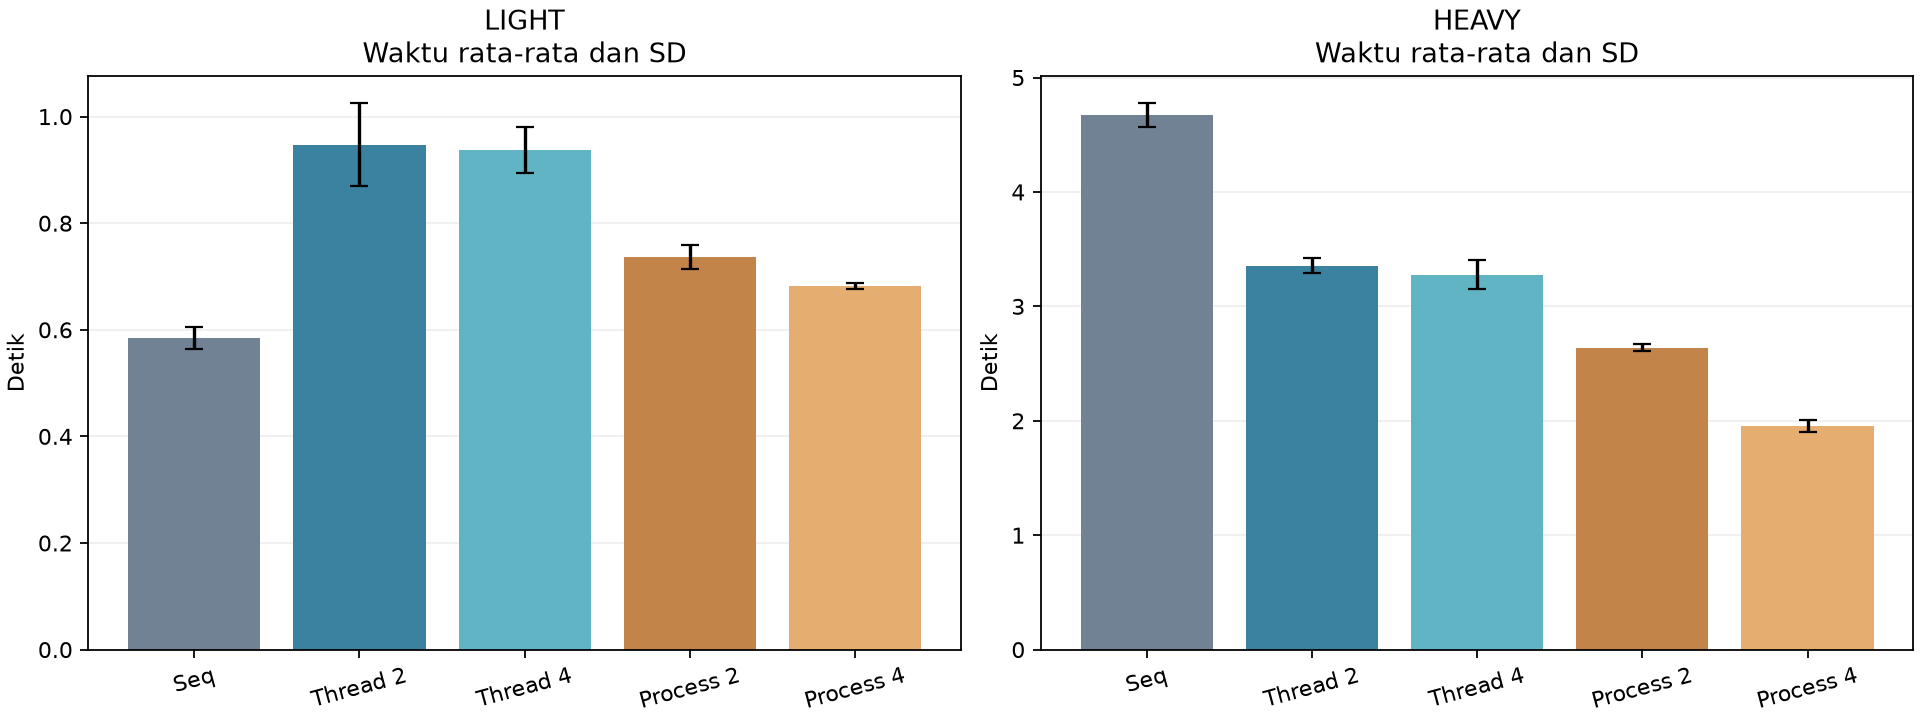

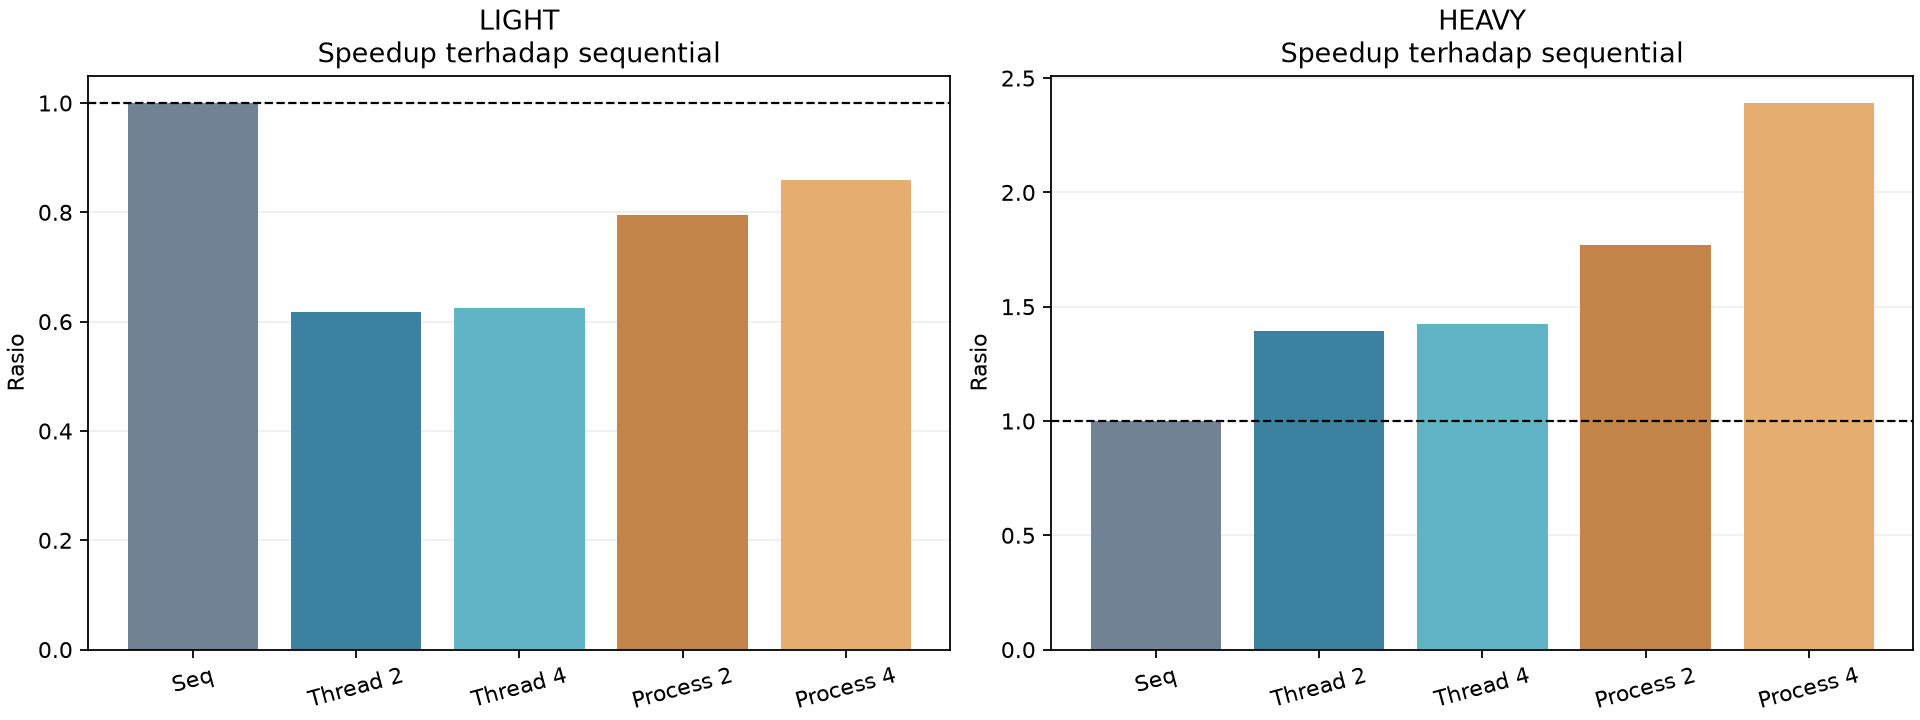

In [6]:
summary = pd.read_csv(RESULT_DIR / "summary.csv")
baseline = summary[summary.method == "sequential"].set_index("workload").mean_time_s
assert np.allclose(summary.speedup, summary.workload.map(baseline) / summary.mean_time_s)
assert np.allclose(summary[summary.method == "sequential"].speedup, 1)
display(summary[["workload", "method", "workers", "runs", "mean_time_s", "std_time_s",
                 "mean_throughput_images_s", "speedup", "efficiency_percent", "time_cv_percent"]].round(3))
display(NotebookImage(filename=str(RESULT_DIR / "figures" / "time_comparison.png")))
display(NotebookImage(filename=str(RESULT_DIR / "figures" / "speedup.png")))

## 7. Perbandingan resource

Saya menampilkan CPU serta RAM untuk parent dan seluruh process tree. Selisih antara RSS parent dan RSS tree memperlihatkan mengapa mencatat parent saja tidak cukup untuk multiprocessing.

Angka CPU yang tinggi tetap harus dibaca bersama waktu dan throughput. Metode yang memakai lebih banyak resource belum tentu menjadi pilihan terbaik untuk pekerjaan singkat. Seluruh kolom resource mempunyai batas sampling yang sudah dijelaskan pada bagian 3.

,workload,method,workers,mean_cpu_tree_sampled_percent,mean_rss_parent_peak_sampled_mib,mean_rss_tree_peak_sampled_mib,max_rss_tree_peak_sampled_mib
0,heavy,sequential,1,97.188,66.751,66.751,66.871
1,heavy,threading,2,156.406,69.402,69.402,69.672
2,heavy,threading,4,190.616,72.374,72.374,72.762
3,heavy,multiprocessing,2,211.425,69.136,146.762,147.184
4,heavy,multiprocessing,4,368.508,69.286,226.257,226.711
5,light,sequential,1,98.369,66.600,66.600,66.645
6,light,threading,2,130.118,68.276,68.276,68.363
7,light,threading,4,134.213,70.342,70.342,70.676
8,light,multiprocessing,2,194.371,68.839,145.519,146.266
9,light,multiprocessing,4,347.333,69.006,221.998,222.473


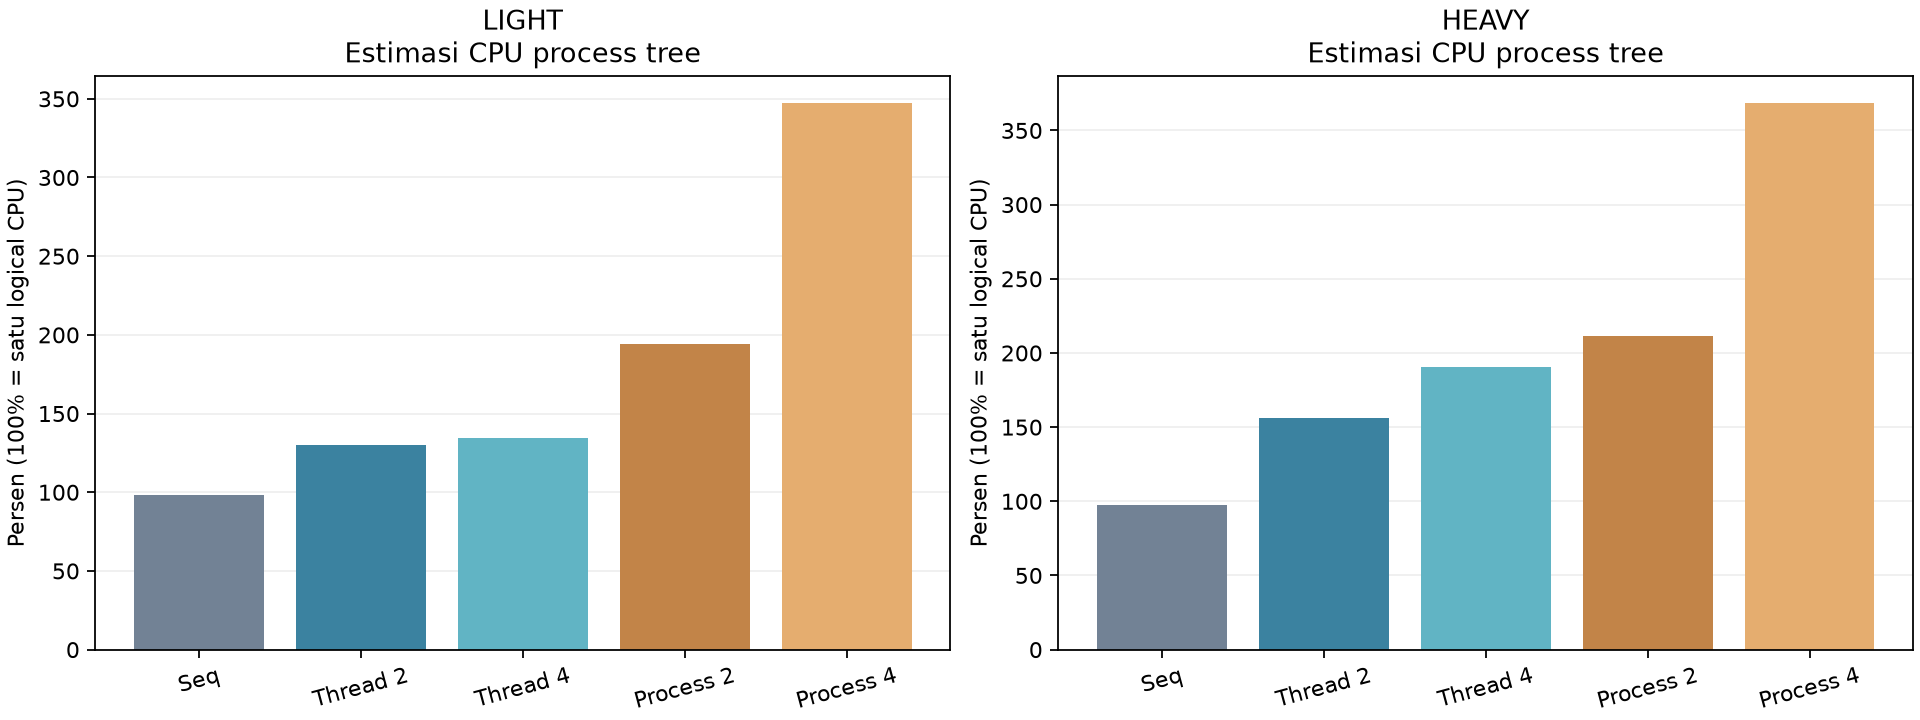

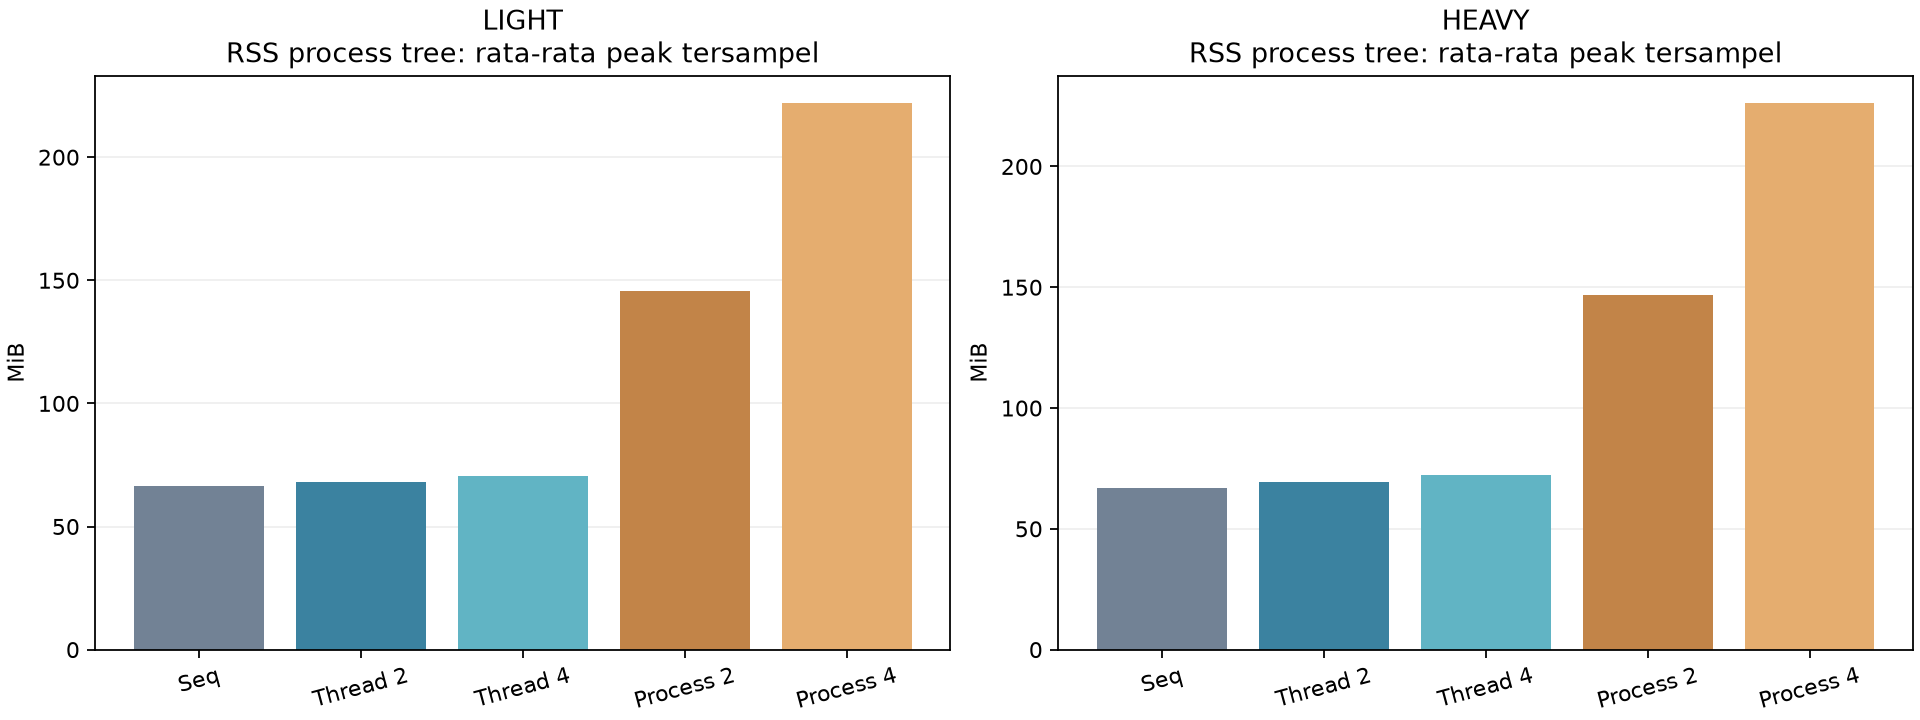

In [7]:
display(summary[["workload", "method", "workers", "mean_cpu_tree_sampled_percent",
                 "mean_rss_parent_peak_sampled_mib", "mean_rss_tree_peak_sampled_mib",
                 "max_rss_tree_peak_sampled_mib"]].round(3))
display(NotebookImage(filename=str(RESULT_DIR / "figures" / "cpu_comparison.png")))
display(NotebookImage(filename=str(RESULT_DIR / "figures" / "memory_comparison.png")))

## 8. Analisis dan kesimpulan hasil

Laporan berikut dihitung dari CSV hasil cell eksperimen. Saya melihat rata-rata tercepat, perubahan ketika worker ditambah, penggunaan RAM, serta variasi run. Penjelasan tentang spawn, GIL, dan IPC digunakan sebagai konteks, bukan dianggap sebagai penyebab tunggal yang sudah dibuktikan.

In [8]:
display(Markdown((RESULT_DIR / "analysis.md").read_text(encoding="utf-8")))

# Analisis Perbandingan Sequential, Multithreading, dan Multiprocessing

Saya menguji 10,000 gambar dari batch pertama CIFAR-10 secara lokal di Windows. Ada lima konfigurasi pada LIGHT dan HEAVY, masing-masing 7 pengulangan. Seluruh angka perbandingan berasal dari rangkaian ini, dengan fungsi transformasi dan pemantauan resource yang sama. Hasil notebook 01 dan 02 tetap menjadi catatan tahap awal.

## Hasil pengukuran

| Workload | Metode | Worker | Waktu rata-rata (s) | SD (s) | Gambar/s | Speedup | Estimasi CPU tree (%) | RSS tree peak rata-rata (MiB) |
|---|---|---:|---:|---:|---:|---:|---:|---:|
| HEAVY | sequential | 1 | 4.672 | 0.106 | 2141.5 | 1.00 | 97.2 | 66.75 |
| HEAVY | threading | 2 | 3.357 | 0.065 | 2979.7 | 1.39 | 156.4 | 69.40 |
| HEAVY | threading | 4 | 3.275 | 0.126 | 3057.2 | 1.43 | 190.6 | 72.37 |
| HEAVY | multiprocessing | 2 | 2.639 | 0.033 | 3790.1 | 1.77 | 211.4 | 146.76 |
| HEAVY | multiprocessing | 4 | 1.954 | 0.052 | 5121.1 | 2.39 | 368.5 | 226.26 |
| LIGHT | sequential | 1 | 0.585 | 0.021 | 17101.8 | 1.00 | 98.4 | 66.60 |
| LIGHT | threading | 2 | 0.947 | 0.078 | 10613.9 | 0.62 | 130.1 | 68.28 |
| LIGHT | threading | 4 | 0.938 | 0.043 | 10680.2 | 0.62 | 134.2 | 70.34 |
| LIGHT | multiprocessing | 2 | 0.737 | 0.022 | 13580.5 | 0.79 | 194.4 | 145.52 |
| LIGHT | multiprocessing | 4 | 0.682 | 0.005 | 14668.4 | 0.86 | 347.3 | 222.00 |

## Analisis per-workload

### LIGHT

Rata-rata tercepat adalah sequential, dengan waktu 0.585 detik dan speedup 1.00. Process 2 membutuhkan 0.737 detik (speedup 0.79), sedangkan process 4 0.682 detik (speedup 0.86). Nilai speedup di bawah 1 menunjukkan lebih lambat dari sequential.

Dari process 2 ke process 4, perubahan waktu rata-rata adalah -7.5%. Angka positif berarti bertambah lambat, angka negatif berarti lebih cepat. Saya tidak menganggap jumlah worker berbanding lurus dengan peningkatan kecepatan.

RSS tree peak tersampel rata-rata meningkat dari 66.60 MiB pada sequential menjadi 145.52 MiB untuk process 2 dan 222.00 MiB untuk process 4. Nilai ini adalah jumlah RSS proses pada snapshot bersamaan, bukan ukuran memori unik.

Konfigurasi dengan waktu terendah pada setiap putaran adalah sequential_1: 7 dari 7 putaran. Setiap putaran berisi seluruh konfigurasi yang dijalankan berurutan, bukan pada saat bersamaan. Hitungan ini menunjukkan konsistensi deskriptif, bukan uji signifikansi.

| Konfigurasi | Median (s) | Minimum (s) | Maksimum (s) | CV waktu (%) |
|---|---:|---:|---:|---:|
| sequential_1 | 0.588 | 0.554 | 0.613 | 3.52 |
| threading_2 | 0.933 | 0.864 | 1.079 | 8.24 |
| threading_4 | 0.925 | 0.903 | 1.025 | 4.60 |
| multiprocessing_2 | 0.731 | 0.703 | 0.768 | 3.04 |
| multiprocessing_4 | 0.682 | 0.672 | 0.687 | 0.76 |

Median saya gunakan sebagai pembanding terhadap rata-rata ketika terdapat run yang jauh lebih lambat. Semua run tetap disertakan dalam CSV dan rata-rata.

### HEAVY

Rata-rata tercepat adalah multiprocessing 4 worker, dengan waktu 1.954 detik dan speedup 2.39. Process 2 membutuhkan 2.639 detik (speedup 1.77), sedangkan process 4 1.954 detik (speedup 2.39). Nilai speedup di bawah 1 menunjukkan lebih lambat dari sequential.

Dari process 2 ke process 4, perubahan waktu rata-rata adalah -26.0%. Angka positif berarti bertambah lambat, angka negatif berarti lebih cepat. Saya tidak menganggap jumlah worker berbanding lurus dengan peningkatan kecepatan.

RSS tree peak tersampel rata-rata meningkat dari 66.75 MiB pada sequential menjadi 146.76 MiB untuk process 2 dan 226.26 MiB untuk process 4. Nilai ini adalah jumlah RSS proses pada snapshot bersamaan, bukan ukuran memori unik.

Konfigurasi dengan waktu terendah pada setiap putaran adalah multiprocessing_4: 7 dari 7 putaran. Setiap putaran berisi seluruh konfigurasi yang dijalankan berurutan, bukan pada saat bersamaan. Hitungan ini menunjukkan konsistensi deskriptif, bukan uji signifikansi.

| Konfigurasi | Median (s) | Minimum (s) | Maksimum (s) | CV waktu (%) |
|---|---:|---:|---:|---:|
| sequential_1 | 4.626 | 4.545 | 4.830 | 2.26 |
| threading_2 | 3.379 | 3.265 | 3.438 | 1.93 |
| threading_4 | 3.244 | 3.156 | 3.528 | 3.86 |
| multiprocessing_2 | 2.644 | 2.572 | 2.674 | 1.24 |
| multiprocessing_4 | 1.952 | 1.896 | 2.058 | 2.67 |

Median saya gunakan sebagai pembanding terhadap rata-rata ketika terdapat run yang jauh lebih lambat. Semua run tetap disertakan dalam CSV dan rata-rata.

## Hubungan hasil dengan Operating System

Thread membaca array input dalam satu proses. Process memiliki interpreter serta ruang alamat sendiri. Implementasi ini mengirim chunk array melalui mekanisme serialization/IPC dan menerima byte output kembali; tidak memakai shared memory. Akibatnya, multiprocessing mengubah biaya koordinasi dan memori, selain jumlah worker.

Worker Windows dibuat dengan spawn. Startup worker, import library di worker, pengiriman data, pemrosesan, pengumpulan output, dan shutdown pool berada di dalam timer. Warm-up 50 gambar hanya dilakukan pada proses utama sebelum timer; worker baru tidak mendapat warm-up sebelumnya. Ini merupakan skenario pool baru per-run, bukan skenario pool persistent. Overhead tersebut merupakan kemungkinan penjelasan hasil, tetapi saya belum mengukurnya sebagai komponen terpisah.

Setiap worker process mempunyai GIL sendiri. Namun menghindari GIL antar-worker tidak menjamin program lebih cepat karena IPC, serialization, serta bagian serial seperti hashing tetap ada. Pada threading, library native dapat melepas GIL. Saya tidak menganggap perbedaan waktu membuktikan GIL sebagai satu-satunya penyebab.

Task pool berisi 100 gambar, dengan maksimum 2 x worker task belum dikonsumsi. Task diambil sesuai urutan pengiriman agar hash sama. Menunggu output awal dapat menghambat pengumpulan output lain. Sequential memproses satu gambar per-iterasi tanpa task pool. Kesimpulan berlaku untuk kebijakan pembagian pekerjaan ini.

## Cara membaca CPU dan RAM

CPU tree mencakup proses benchmark dan turunannya, dengan 100% setara satu logical CPU. Komputer ini memiliki 22 logical CPU. Persentase dapat melebihi 100%, tetapi bukan total penggunaan seluruh CPU komputer.

CPU proses utama dihitung dari perubahan CPU time selama timer. CPU worker dihitung dari nilai kumulatif terakhir yang sempat diamati; snapshot diambil sebelum shutdown agar worker yang masih hidup tercatat. Sebagian CPU teardown setelah snapshot terakhir dapat tidak tercatat. Karena itu kolom CPU tree adalah estimasi tersampel, bukan pengukuran CPU total yang sepenuhnya presisi.

RAM diambil tiap sekitar 50 ms dengan monitor thread yang sama untuk semua metode, serta snapshot di awal, sebelum shutdown pool, dan di akhir. Yang dilaporkan adalah maksimum jumlah RSS pada snapshot, bukan penjumlahan peak tiap proses pada waktu berbeda. Halaman memori shared bisa dihitung lebih dari sekali; puncak singkat dan perubahan proses saat snapshot bisa terlewat. Angka ini bukan unique memory/PSS atau seluruh RAM komputer. Overhead monitor ikut memengaruhi semua kondisi.

## Validasi dan keterbatasan

Semua konfigurasi pada workload yang sama menghasilkan hash SHA-256 yang sama. Jumlah output dan rumus throughput juga diperiksa. Hash membuktikan konsistensi byte output pada input ini, bukan penilaian kualitas visual.

7 pengulangan memberi gambaran variasi yang lebih lengkap, tetapi bukan uji signifikansi. Input ringan yang selesai di bawah satu detik sensitif terhadap gangguan kecil. Urutan konfigurasi diputar, tetapi temperatur, background task, serta pemilihan core tidak dikendalikan atau dicatat. Saya belum membandingkan input lebih besar, chunk lain, shared memory, pool persistent, atau pipeline penyimpanan file.

Metode monitoring pada tahap ini berbeda dari notebook 01/02. Karena itu, perbandingan akhir hanya memakai CSV rangkaian ini; angka CPU/RAM lama tidak dicampur dengan kolom process tree baru. Error bar adalah sample SD, bukan confidence interval.

## Kesimpulan

Berdasarkan rata-rata yang terukur, konfigurasi tercepat adalah LIGHT: sequential; HEAVY: multiprocessing 4 worker. Saya membaca pilihan tersebut bersama biaya CPU/RAM dan variasi run. Hasil ini menunjukkan pilihan metode perlu disesuaikan dengan workload serta biaya koordinasi, bukan sekadar memilih jumlah worker terbanyak. Kesimpulan terbatas pada kondisi lokal ini.

## Referensi

- https://docs.python.org/3.11/library/concurrent.futures.html#concurrent.futures.ProcessPoolExecutor
- https://docs.python.org/3.11/library/multiprocessing.html#contexts-and-start-methods
- https://psutil.readthedocs.io/
- https://www.cs.toronto.edu/~kriz/cifar.html


## 9. Batas kesimpulan dan rencana pengembangan

Saya sudah menguji seluruh konfigurasi yang direncanakan: sequential, thread 2/4, dan process 2/4. Hasil berlaku pada 10.000 gambar, ukuran kerja 64 × 64, chunk 100, antrean terbatas, pool baru, dan kondisi komputer saat pengujian.

Untuk memperkuat kesimpulan, pengembangan berikutnya bisa memakai lebih banyak pengulangan, input yang lebih besar, pengujian chunk size lain, atau pool persistent. Perubahan tersebut harus diterapkan dan dilaporkan secara konsisten, supaya hasil tidak dicampur dengan skenario awal.

## Referensi

- [ProcessPoolExecutor — Python 3.11](https://docs.python.org/3.11/library/concurrent.futures.html#concurrent.futures.ProcessPoolExecutor).
- [Start methods dan spawn — Python 3.11](https://docs.python.org/3.11/library/multiprocessing.html#contexts-and-start-methods).
- [psutil — resource process](https://psutil.readthedocs.io/).
- [CIFAR-10](https://www.cs.toronto.edu/~kriz/cifar.html).

## 10. Memeriksa konsistensi seluruh pengulangan

Saya membandingkan median dengan rata-rata, lalu melihat minimum, maksimum, dan CV. Jika ada run lambat, nilai rata-rata dapat bergeser; median membantu memperlihatkan posisi tengah tanpa membuang run tersebut.

Setiap titik pada grafik menunjukkan satu run, dan garis hitam menunjukkan median. Saya juga menghitung konfigurasi tercepat dalam setiap putaran. Karena seluruh kondisi dalam satu putaran dijalankan berurutan, hitungan ini membantu membaca konsistensi, tetapi bukan kontrol kondisi komputer secara sempurna.

,workload,method,workers,mean_time_s,median_time_s,std_time_s,min_time_s,max_time_s,time_cv_percent
0,heavy,sequential,1,4.672,4.626,0.106,4.545,4.830,2.264
1,heavy,threading,2,3.357,3.379,0.065,3.265,3.438,1.929
2,heavy,threading,4,3.275,3.244,0.126,3.156,3.528,3.860
3,heavy,multiprocessing,2,2.639,2.644,0.033,2.572,2.674,1.238
4,heavy,multiprocessing,4,1.954,1.952,0.052,1.896,2.058,2.668
5,light,sequential,1,0.585,0.588,0.021,0.554,0.613,3.519
6,light,threading,2,0.947,0.933,0.078,0.864,1.079,8.244
7,light,threading,4,0.938,0.925,0.043,0.903,1.025,4.600
8,light,multiprocessing,2,0.737,0.731,0.022,0.703,0.768,3.042
9,light,multiprocessing,4,0.682,0.682,0.005,0.672,0.687,0.765


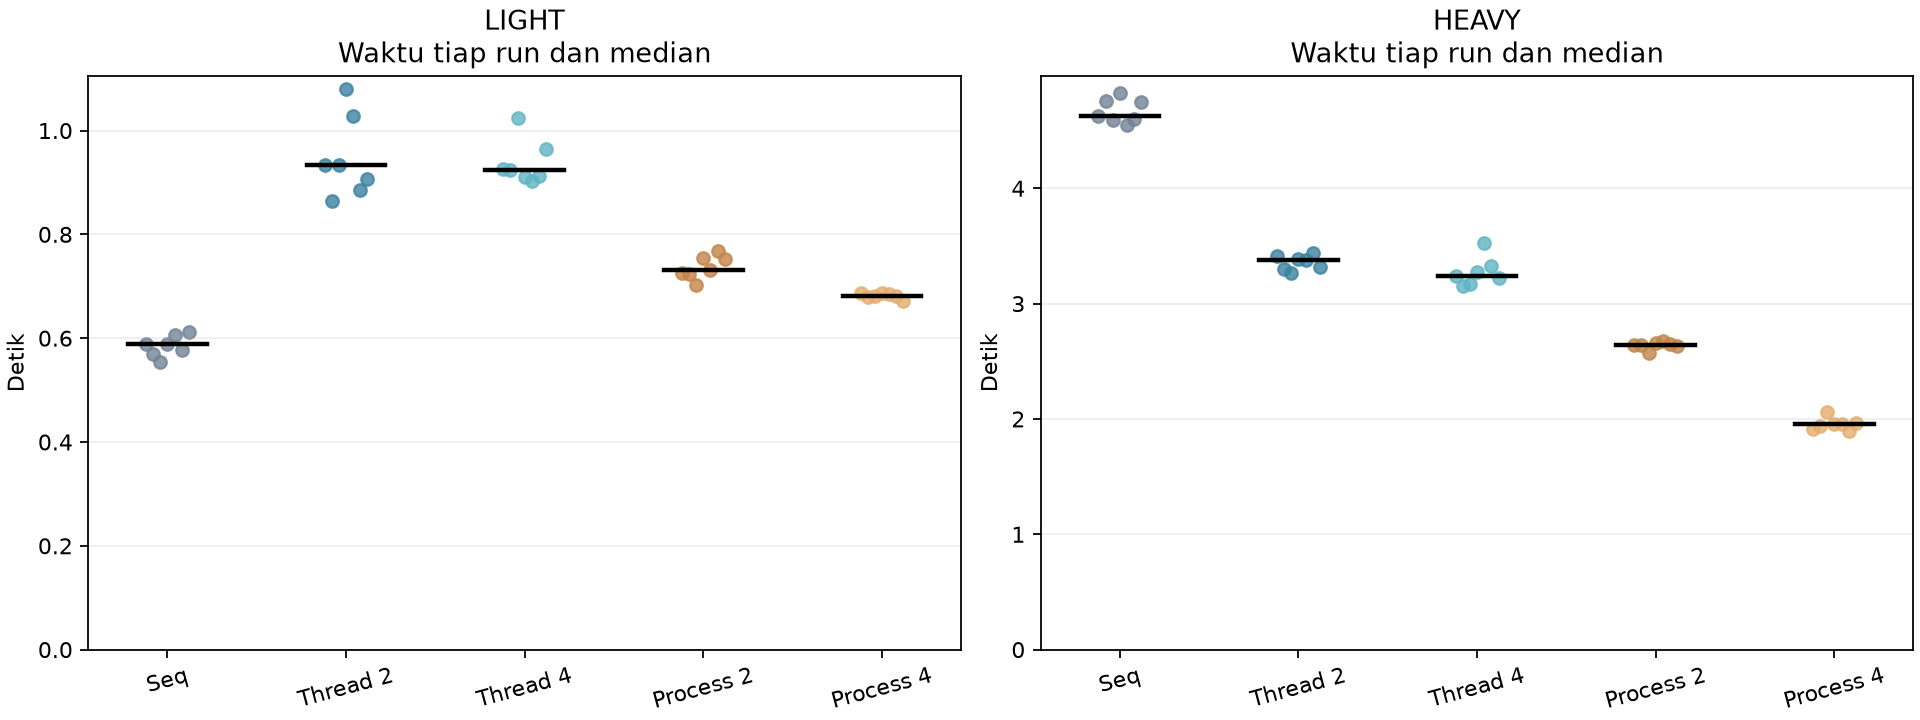

,workload,configuration,putaran_tercepat
0,heavy,multiprocessing_4,7
1,light,sequential_1,7


In [9]:
display(summary[["workload", "method", "workers", "mean_time_s", "median_time_s",
                 "std_time_s", "min_time_s", "max_time_s", "time_cv_percent"]].round(3))
display(NotebookImage(filename=str(RESULT_DIR / "figures" / "run_distribution.png")))
fastest_per_round = pd.read_csv(RESULT_DIR / "fastest_per_round.csv")
assert len(fastest_per_round) == 2 * REPETITIONS
counts = fastest_per_round.groupby(["workload", "configuration"]).size().rename("putaran_tercepat").reset_index()
display(counts)

## 11. Menyimpan laporan akhir

Laporan berikut merangkum latar belakang, tujuan, data, lingkungan pengujian, metode, grafik, hasil, analisis, dan keterbatasan. Saya menyimpan grafik bersama laporan dan menghubungkan angka dengan CSV rangkaian ini agar hasilnya dapat diperiksa kembali.

Bahasa laporan memakai sudut pandang saya dengan penjelasan yang sesuai materi eksperimen. Sebelum dipresentasikan, saya perlu memahami arti speedup, batas CPU/RAM tersampel, biaya startup worker, serta pengaruh variasi antar-run.

In [10]:
from final_report import make_final_report
FINAL_REPORT = make_final_report(RESULT_DIR, PROJECT)
assert FINAL_REPORT.is_file()
print("Laporan akhir:", FINAL_REPORT)
print("Hasil pengukuran:", RESULT_DIR)

Laporan akhir: C:\Lucky\Binus University\S9\Operating System\Operating-System-Assignment\reports\20261005_135845_282190\Laporan_Akhir.md
Hasil pengukuran: C:\Lucky\Binus University\S9\Operating System\Operating-System-Assignment\results\comparison\20261005_135845_282190
